# Activation Foil Analysis: 1L BABY Run #1

This notebook processes the calibration data from NaI detectors to energy calibrate the detectors and determine total detector efficiencies. Then, NaI measurements of activation foils irradiated during the run with a D-T neutron (14.1 MeV) generator are used to determine the average neutron rate during the run. 

## Obtaining the Data
First, the NaI detector measurement data is obtained from Zenodo and extracted

In [1]:
# parameters

## keep this if statement for ci and process workflows
if 'download_from_raw' not in globals() and 'download_from_raw' not in locals():
    download_from_raw = False

In [2]:
import numpy as np
from datetime import datetime
import json

In [3]:
from process_foil_data import get_data
check_source_measurements, background_meas, foil_measurements = get_data(download_from_raw=download_from_raw)


Read in properties of Nb1 foil
Read in properties of Zr Packet #1 foil
Processing Background from h5 file...
Processing Co60 Count 1 from h5 file...
Processing Cs137 Count 1 from h5 file...
Processing Mn54 Count 1 from h5 file...
Processing Nb1 Count 1 from h5 file...
Processing Zr Packet #1 Count 1 from h5 file...


## Energy Calibration

Using gamma check sources like Co-60 and Cs-137, the characteristic photon peaks from these sources are used to convert the digitizer channel bins into energy (keV) bins

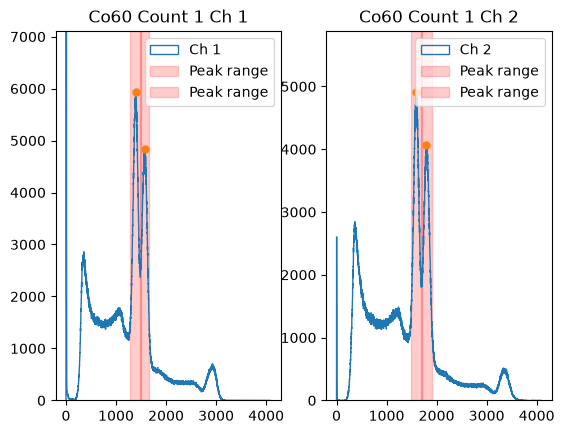

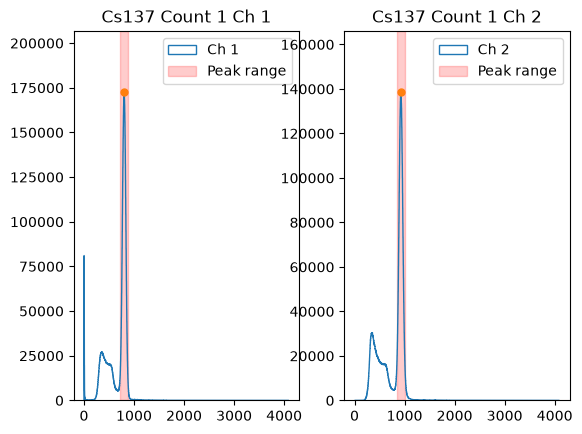

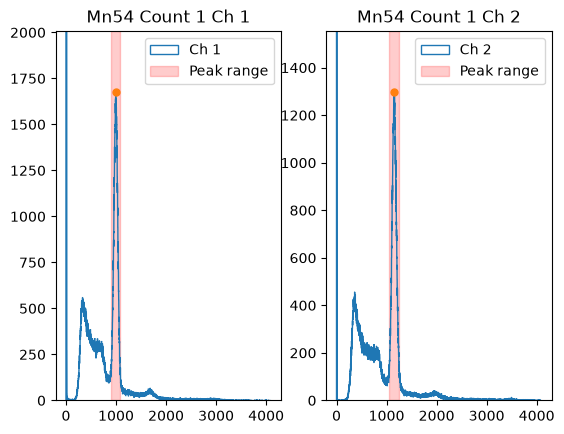

In [4]:
import matplotlib.pyplot as plt
from libra_toolbox.neutron_detection.activation_foils import compass

for meas_name in check_source_measurements:
    fig, ax = plt.subplots(ncols=2)
    for a,detector in enumerate(check_source_measurements[meas_name].detectors):
        
        hist, bin_edges = detector.get_energy_hist()

        ax[a].hist(
            bin_edges[:-1],
            bins=bin_edges,
            weights=hist,
            histtype="step",
            label=f"Ch {detector.channel_nb}",
        )
        peaks = check_source_measurements[meas_name].get_peaks(hist)

        from scipy.signal import find_peaks
        import numpy as np

        start_index = 400
        height = 0.60 * np.max(hist[start_index:])
        prominence = None
        width = [10, 150]
        distance = 30
        peaks, peak_data = find_peaks(
            hist[start_index:],
            prominence=prominence,
            height=height,
            width=width,
            distance=distance,
        )
        ax[a].plot(bin_edges[start_index:][peaks], peak_data["peak_heights"], ".", ms=10)

        for i, p in enumerate(peaks):
            width = peak_data["widths"][i]
            ax[a].axvspan(
                bin_edges[start_index:][p] - width,
                bin_edges[start_index:][p] + width,
                color="red",
                alpha=0.2,
                label="Peak range"
            )
        ax[a].set_ylim(0, height*2)
        ax[a].set_title(meas_name + f' Ch {detector.channel_nb}')
        ax[a].legend()

    # plt.yscale("log")
plt.show()

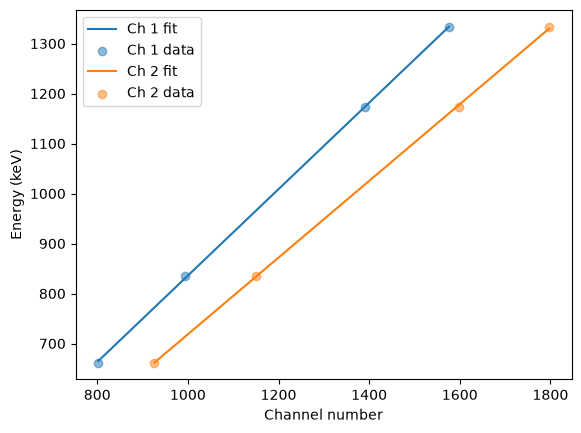

In [5]:
calibration_coeffs = {}

for channel_nb in [1, 2]:
    calibration_channels, calibration_energies = compass.get_calibration_data(
        check_source_measurements.values(),
        background_measurement=background_meas,
        channel_nb=channel_nb,
    )

    coeff = np.polyfit(calibration_channels, calibration_energies, 1)
    calibration_coeffs[channel_nb] = coeff

    xs = np.linspace(
        calibration_channels[0],
        calibration_channels[-1],
    )
    plt.plot(
        xs,
        np.polyval(coeff, xs),
        label=f"Ch {channel_nb} fit",
    )
    plt.scatter(
        calibration_channels,
        calibration_energies,
        label=f"Ch {channel_nb} data",
        alpha=0.5,
    )
plt.xlabel("Channel number")
plt.ylabel("Energy (keV)")
plt.legend()
plt.show()

## Detector Efficiency

Using these same check-sources, each with a known activity, an efficiency curve for each detector is calculated. 

Two types of efficiency curves are shown: 
1. Exponent of sum of logarithms (used in https://doi.org/10.2172/1524045): $ y = \exp(\sum_{i=0}^n a_n \log(E)^i) $

2. Polynomial fit (3rd order): $ y = \sum_{i=0}^n a_n E^i $

**Only the polynomal fit is currently implemented in libra-toolbox, so that is the curve that will be used to calculate the efficiency of the detectors at measuring the activity of the activation foil peaks.**

In [6]:
def eff_curve_func(E, *a):
    exponent_term = 0
    for i,a_n in enumerate(a):
        exponent_term += a_n * (np.log(E) ** i)
    return np.exp(exponent_term)

[1172.96655933 1333.71000562]
Fitted parameters: [ 2.67933619e+03 -1.43958926e+00  4.84016550e+03  1.17528996e+03
  4.12024585e+01  4.04428418e+03  1.33149250e+03  4.39466694e+01]
[664.80985815]
Fitted parameters: [ 3.02493759e+04 -3.47681812e+01  1.67242678e+05  6.65591940e+02
 -2.75536537e+01]
[830.7385769]
Fitted parameters: [ 3.54811200e+02 -3.36607071e-01  1.50182052e+03  8.33164372e+02
  3.16703244e+01]
Ch 1 
	 Energies: [ 661.657  834.848 1173.228 1332.492], 
	 Efficiencies: [0.17897786 0.18256939 0.07757537 0.06904493]
[1177.15999381 1329.79471702]
Fitted parameters: [ 2.02982567e+03 -1.03248027e+00  3.99322465e+03  1.17435623e+03
  3.90761870e+01  3.34005020e+03  1.33356571e+03  4.37334998e+01]
[661.73017474]
Fitted parameters: [ 2.38179881e+04 -2.71574074e+01  1.33216869e+05  6.62969599e+02
 -2.77020490e+01]
[833.54011443]
Fitted parameters: [ 2.48143485e+02 -2.36747038e-01  1.16179832e+03  8.36386957e+02
  3.15091125e+01]
Ch 2 
	 Energies: [ 661.657  834.848 1173.228 1332.49

/var/folders/5m/rvw0b3wn2c181dfbtvzl6prr0000gn/T/ipykernel_71013/1717222888.py:42: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(


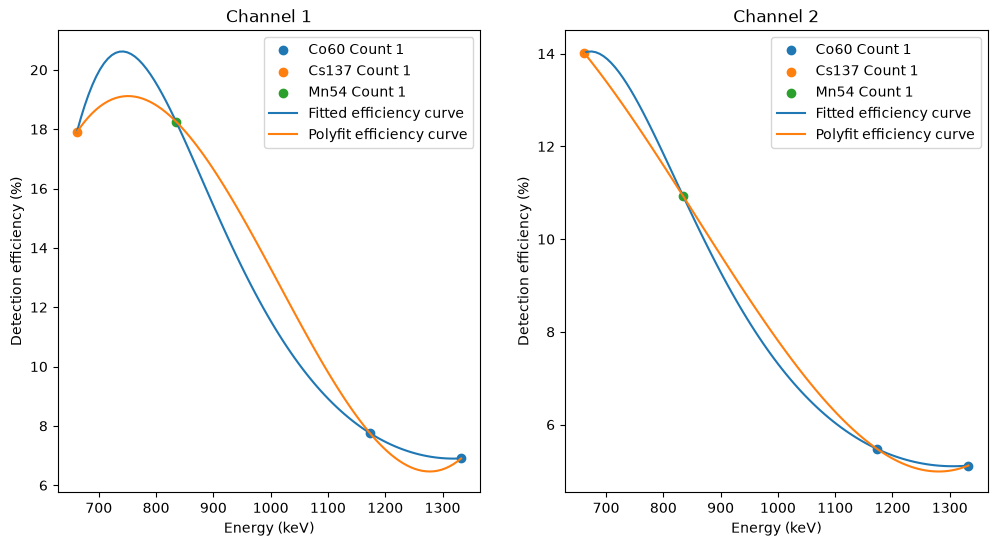

In [7]:
from scipy.optimize import curve_fit

channels = []
efficiency_coeffs = {}
measurement = list(check_source_measurements.values())[0]
search_width = 330

for detector in measurement.detectors:
    channels.append(detector.channel_nb)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))
for i,ch in enumerate(channels):
    background_detector = background_meas.get_detector(ch)
    energies = []
    efficiencies = []
    for name, measurement in check_source_measurements.items():
        check_source_detector = measurement.get_detector(ch)
        hist, bin_edges = check_source_detector.get_energy_hist_background_substract(background_detector)
        calibrated_bin_edges = np.polyval(calibration_coeffs[ch], bin_edges)
        
        efficiency = measurement.compute_detection_efficiency(
            background_measurement=background_meas,
            calibration_coeffs=calibration_coeffs[ch],
            channel_nb=ch,
            search_width=search_width,
        )
        energies += measurement.check_source.nuclide.energy
        efficiencies += list(efficiency)
        ax[i].scatter(
            measurement.check_source.nuclide.energy,
            efficiency * 100,
            label=name,
        )

    # Sort energies and efficiencies for fitting
    sorted_indices = np.argsort(energies)
    energies = np.array(energies)[sorted_indices]
    efficiencies = np.array(efficiencies)[sorted_indices]
    print(f"Ch {ch} \n\t Energies: {energies}, \n\t Efficiencies: {efficiencies}")

    # Fit the efficiency curve
    popt, pcov = curve_fit(
        eff_curve_func,
        energies,
        efficiencies,
        p0=[-1, 1, 0, 0],
    )

    poly_coeff = np.polyfit(energies, efficiencies, 3)
    efficiency_coeffs[ch] = poly_coeff
    xs = np.linspace(
        energies[0],
        energies[-1],
        100,
    )
    ax[i].plot(
        xs,
        eff_curve_func(xs, *popt) * 100,
        label="Fitted efficiency curve",
    )

    ax[i].plot(
        xs,
        np.polyval(poly_coeff, xs) * 100,
        label="Polyfit efficiency curve",
    )
    ax[i].set_xlabel("Energy (keV)")
    ax[i].set_ylabel("Detection efficiency (%)")
    ax[i].set_title(f"Channel {ch}")
    ax[i].legend()
plt.show()

## Calculating average neutron rate from activation foils

First, the irradiation schedule and the foil information is collected.

In [8]:
all_neutron_rates = []
all_neutron_rates_err = []

In [9]:
from process_foil_data import irradiations, time_generator_off

### Niobium Packet #3 Results

The activity of Nb-92m is measured using its 934 keV gamma peak and used to determine the neutron rate during the irradiation. Nb-92m is formed from the Nb-93(n,2n) reaction, which has a threshold energy of 8.9 MeV. 

The gamma spectrum obtained from the various measurements of the Niobium Packet #3 after irradiation are used to calculate the neutron rate of the overall irradiation. 

In [10]:
from process_foil_data import calculate_neutron_rate_from_foil

foil_name = "Nb1"

neutron_rates, neutron_rate_errs = calculate_neutron_rate_from_foil(foil_measurements,
                                                                    foil_name,
                                                                    background_meas,
                                                                    calibration_coeffs,
                                                                    efficiency_coeffs,
                                                                    search_width=search_width)

for count_name in neutron_rates.keys():
    print(count_name)
    for ch in np.sort(list(neutron_rates[count_name].keys())):
        neutron_rate = neutron_rates[count_name][ch]
        neutron_rate_err = neutron_rate_errs[count_name][ch]
        print(f"\t Ch {ch}: Neutron rate: {neutron_rate[0]:.3e} +/- {neutron_rate_err[0]:.3e} n/s")
        all_neutron_rates.append(neutron_rate[0])
        all_neutron_rates_err.append(neutron_rate_err[0])


[934.44]
Fitted parameters: [ 2.08828096e+02 -1.43837571e-01  2.45839663e+02  9.33402869e+02
  3.43504803e+01]
[934.44]
Fitted parameters: [ 4.28240365e+01 -3.64271098e-02  2.14420865e+02  9.35571865e+02
  3.32332918e+01]
Count 1
	 Ch 1: Neutron rate: 8.622e+07 +/- 5.934e+05 n/s
	 Ch 2: Neutron rate: 1.039e+08 +/- 7.787e+05 n/s


### Zirconium Packet #1 Results

The activity of Zr-89 is measured using its 909 keV gamma peak and used to determine the neutron rate during the irradiation. Zr-89 m is formed from the Zr-90(n,2n) reaction, which has a threshold energy of 12.1 MeV. 

The gamma spectrum obtained from the various measurements of the Zirconium Packet #1 after irradiation are used to calculate the neutron rate of the overall irradiation. 

In [11]:
foil_name = "Zr Packet #1"

neutron_rates, neutron_rate_errs = calculate_neutron_rate_from_foil(foil_measurements,
                                                                    foil_name,
                                                                    background_meas,
                                                                    calibration_coeffs,
                                                                    efficiency_coeffs,
                                                                    search_width=search_width)

for count_name in neutron_rates.keys():
    print(count_name)
    for ch in np.sort(list(neutron_rates[count_name].keys())):
        neutron_rate = neutron_rates[count_name][ch]
        neutron_rate_err = neutron_rate_errs[count_name][ch]
        print(f"\t Ch {ch}: Neutron rate: {neutron_rate[0]:.3e} +/- {neutron_rate_err[0]:.3e} n/s")
        all_neutron_rates.append(neutron_rate[0])
        all_neutron_rates_err.append(neutron_rate_err[0])

[909.15]
Fitted parameters: [ 1.04662809e+03 -9.05130303e-01  2.88278683e+03  9.19865599e+02
  2.96027046e+01]
[909.15]
Fitted parameters: [ 8.37430426e+02 -7.37475048e-01  2.59959821e+03  9.06398852e+02
  2.95828365e+01]
Count 1
	 Ch 1: Neutron rate: 6.266e+07 +/- 1.357e+05 n/s
	 Ch 2: Neutron rate: 9.054e+07 +/- 2.065e+05 n/s


### Averaging foil results

The average of the neutron rates of the Niobium and Zirconium foil packets is calculated and added to the processed_data.json file. 

In [12]:
average_neutron_rate = np.mean(all_neutron_rates)
# average_neutron_rate_err = np.sqrt(np.sum(np.array(all_neutron_rates_err) ** 2)) / len(all_neutron_rates_err)
average_neutron_rate_err = np.std(all_neutron_rates, ddof=1)  # Use ddof=1 for sample standard deviation

print(f"Average neutron rate: {average_neutron_rate:.3e} ± {average_neutron_rate_err:.3e} n/s")

Average neutron rate: 8.583e+07 ± 1.719e+07 n/s


In [13]:
processed_data_file = "../../data/processed_data.json"

processed_data = {
    "neutron_rate_used_in_model": {
        "value":average_neutron_rate,
        "error": average_neutron_rate_err,
        "unit": "neutron / second"
    }
}

try:
    with open(processed_data_file, "r") as f:
        existing_data = json.load(f)
except FileNotFoundError:
    print(f"Processed data file not found, creating it in {processed_data_file}")
    existing_data = {}

existing_data.update(processed_data)

with open(processed_data_file, "w") as f:
    json.dump(existing_data, f, indent=4)

print(f"Processed data stored in {processed_data_file}")

Processed data stored in ../../data/processed_data.json
